In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [37]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.reshape(-1, 1).astype(float)

rng = np.random.default_rng(42)
train_idx, val_idx, test_idx = [], [], []

for cls in np.unique(y):
    idx = np.where(y.ravel() == cls)[0]
    rng.shuffle(idx)

    n_train = int(len(idx) * 0.64)
    n_val = int(len(idx) * 0.16)

    train_idx.extend(idx[:n_train])
    val_idx.extend(idx[n_train:n_train+n_val])
    test_idx.extend(idx[n_train+n_val:])

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (192, 13)
Validation: (48, 13)
Testing: (62, 13)


In [38]:
def sigmoid(x):
    x = np.clip(x, -20, 20)
    return 1 / (1 + np.exp(-x))


def train_network(X, y, architecture, epochs=100, lr=0.01):

    rng = np.random.default_rng(42)

    sizes = [X.shape[1]] + list(architecture) + [1]
    weights, biases = [], []

    for i in range(len(sizes) - 1):
        weights.append(
            rng.normal(0, np.sqrt(2 / sizes[i]),
                       (sizes[i], sizes[i+1]))
        )
        biases.append(np.zeros((1, sizes[i+1])))

    for epoch in range(epochs):

        activations = [X]
        pre_activations = []

        for i in range(len(weights)):

            z = activations[-1] @ weights[i] + biases[i]
            pre_activations.append(z)

            if i == len(weights) - 1:
                a = sigmoid(z)
            else:
                a = np.maximum(0, z)

            activations.append(a)

        m = len(y)
        delta = (activations[-1] - y) / m

        for i in reversed(range(len(weights))):

            dw = activations[i].T @ delta
            db = np.sum(delta, axis=0, keepdims=True)

            if i > 0:
                delta = (delta @ weights[i].T) * (
                    pre_activations[i-1] > 0
                )

            weights[i] -= lr * dw
            biases[i] -= lr * db

    return weights, biases


def predict_network(X, weights, biases):

    a = X

    for i in range(len(weights)):
        z = a @ weights[i] + biases[i]

        if i == len(weights) - 1:
            a = sigmoid(z)
        else:
            a = np.maximum(0, z)

    return a

In [39]:
architectures = [
    (16,),
    (32,),
    (64,),
    (16, 8),
    (32, 16),
    (64, 32),
    (32, 16, 8),
    (64, 32, 16),
    (64, 64),
    (128, 64)
]

print("Total Architectures:", len(architectures))
for i, arch in enumerate(architectures):
    print(i, arch)

Total Architectures: 10
0 (16,)
1 (32,)
2 (64,)
3 (16, 8)
4 (32, 16)
5 (64, 32)
6 (32, 16, 8)
7 (64, 32, 16)
8 (64, 64)
9 (128, 64)


In [40]:
def rbf_kernel(X1, X2, length_scale=2):

    distances = (
        np.sum(X1**2, axis=1).reshape(-1, 1)
        + np.sum(X2**2, axis=1).reshape(1, -1)
        - 2 * (X1 @ X2.T)
    )

    return np.exp(
        -np.maximum(distances, 0) / (2 * length_scale**2)
    )


def gaussian_process(X_train_gp, y_train_gp, X_candidates):

    K = rbf_kernel(X_train_gp, X_train_gp) + 1e-6 * np.eye(len(X_train_gp))
    K_s = rbf_kernel(X_train_gp, X_candidates)
    K_ss = rbf_kernel(X_candidates, X_candidates)

    alpha = np.linalg.solve(K, y_train_gp)

    mean = K_s.T @ alpha

    variance = np.diag(
        K_ss - K_s.T @ np.linalg.solve(K, K_s)
    )

    std = np.sqrt(np.maximum(variance, 1e-10))

    return mean.ravel(), std

In [41]:
import math

def expected_improvement(mean, std, best_score, xi=0.01):

    improvement = mean - best_score - xi
    z = improvement / std

    cdf = np.array([
        0.5 * (1 + math.erf(value / np.sqrt(2)))
        for value in z
    ])

    pdf = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

    ei = improvement * cdf + std * pdf

    return np.maximum(ei, 0)

In [42]:
X_candidates = np.array([
    [len(a), sum(a), max(a)] for a in architectures
], dtype=float)

X_candidates = (
    X_candidates - X_candidates.mean(axis=0)
) / (X_candidates.std(axis=0) + 1e-8)

evaluated = []
scores = []

initial_indices = [0, 2, 4]

for idx in initial_indices:

    arch = architectures[idx]

    weights, biases = train_network(
        X_train, y_train, arch
    )

    val_pred = predict_network(X_val, weights, biases)
    score = np.mean((val_pred >= 0.5) == y_val)

    evaluated.append(idx)
    scores.append(score)

    print("Architecture:", arch, "| Validation Accuracy:", round(score * 100, 2))

Architecture: (16,) | Validation Accuracy: 64.58
Architecture: (64,) | Validation Accuracy: 72.92
Architecture: (32, 16) | Validation Accuracy: 70.83


In [43]:
n_iterations = 5

for iteration in range(n_iterations):

    remaining = [
        i for i in range(len(architectures))
        if i not in evaluated
    ]

    gp_X = X_candidates[evaluated]
    gp_y = np.array(scores)

    mean, std = gaussian_process(
        gp_X, gp_y, X_candidates[remaining]
    )

    ei = expected_improvement(
        mean, std, max(scores)
    )

    next_idx = remaining[np.argmax(ei)]
    arch = architectures[next_idx]

    weights, biases = train_network(
        X_train, y_train, arch
    )

    val_pred = predict_network(
        X_val, weights, biases
    )

    score = np.mean(
        (val_pred >= 0.5) == y_val
    )

    evaluated.append(next_idx)
    scores.append(score)

    print(
        f"Iteration {iteration + 1}: "
        f"Architecture = {arch}, "
        f"Validation Accuracy = {score * 100:.2f}%"
    )

print("\nBayesian Optimization Completed.")

Iteration 1: Architecture = (64, 64), Validation Accuracy = 79.17%
Iteration 2: Architecture = (128, 64), Validation Accuracy = 77.08%
Iteration 3: Architecture = (64, 32, 16), Validation Accuracy = 83.33%
Iteration 4: Architecture = (32, 16, 8), Validation Accuracy = 62.50%
Iteration 5: Architecture = (64, 32), Validation Accuracy = 75.00%

Bayesian Optimization Completed.


In [44]:
best_position = np.argmax(scores)

best_index = evaluated[best_position]
best_architecture = architectures[best_index]
best_score = scores[best_position]

print("Best Architecture:", best_architecture)
print("Best Validation Accuracy:", round(best_score * 100, 2), "%")

Best Architecture: (64, 32, 16)
Best Validation Accuracy: 83.33 %


In [45]:
X_final = np.vstack((X_train, X_val))
y_final = np.vstack((y_train, y_val))

final_weights, final_biases = train_network(
    X_final,
    y_final,
    best_architecture,
    epochs=100
)

test_probabilities = predict_network(
    X_test, final_weights, final_biases
)

test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = np.mean(
    test_predictions == y_test
) * 100

print("Selected Architecture:", best_architecture)
print("Final Test Accuracy:", round(test_accuracy, 2), "%")

Selected Architecture: (64, 32, 16)
Final Test Accuracy: 74.19 %


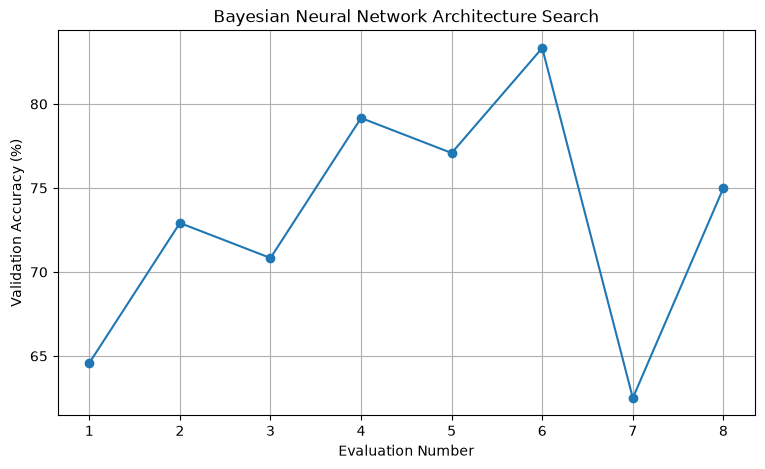

In [47]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(scores) + 1),
    np.array(scores) * 100,
    marker="o"
)

plt.xlabel("Evaluation Number")
plt.ylabel("Validation Accuracy (%)")
plt.title("Bayesian Neural Network Architecture Search")
plt.grid()
plt.show()

In [48]:
search_results = pd.DataFrame({
    "Architecture": [str(architectures[i]) for i in evaluated],
    "Validation Accuracy (%)": np.array(scores) * 100
})

display(search_results.sort_values(
    "Validation Accuracy (%)", ascending=False
).reset_index(drop=True))

,Architecture,Validation Accuracy (%)
0,"(64, 32, 16)",83.333333
1,"(64, 64)",79.166667
2,"(128, 64)",77.083333
3,"(64, 32)",75.000000
4,"(64,)",72.916667
5,"(32, 16)",70.833333
6,"(16,)",64.583333
7,"(32, 16, 8)",62.500000


## Conclusion

In this task, neural network architecture optimization was
performed using a manually implemented Bayesian optimization
approach.

Different architectures with varying hidden layers and neuron
counts were evaluated.

Gaussian Process Regression estimated the performance of
untested architectures, while Expected Improvement selected
promising configurations for further evaluation.

The best architecture was selected using validation accuracy,
retrained on the combined training and validation datasets,
and evaluated on an independent test dataset.

This demonstrates Bayesian hyperparameter optimization
without using built-in optimization libraries.